In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Run this cell 

# Set seed for reproducibility
np.random.seed(42)

# --- EXERCISE 1 DATA (Algorithm Execution Times) ---
ex1_data = pd.DataFrame({
    'Algorithm': np.repeat(['Algorithm A', 'Algorithm B', 'Algorithm C'], 50),
    'Runtime_ms': np.concatenate([
        np.random.normal(45.5, 3.2, 50),
        np.random.normal(32.1, 2.1, 50),
        np.random.normal(38.4, 4.5, 50)
    ])
})
ex1_stats = ex1_data.groupby('Algorithm').agg(['mean', 'std']).round(2)

# --- EXERCISE 2 DATA (Network Latency with Outliers) ---
payload_size = np.random.uniform(10, 100, 100)
latency = 2.5 * payload_size + np.random.normal(0, 15, 100)
# Inject specific outliers
payload_size = np.append(payload_size, [85, 90, 95, 92, 88])
latency = np.append(latency, [40, 35, 45, 38, 42]) 
ex2_data = pd.DataFrame({'Payload_MB': payload_size, 'Latency_ms': latency})
ex2_corr = ex2_data.corr().iloc[0,1].round(2)

# --- EXERCISE 3 DATA (Quarterly Engagement) ---
months = pd.date_range(start='2026-01-01', periods=12, freq='ME')
engagement = [1000, 1150, 1300, 1420, 1580, 1750, 1900, 2100, 2250, 1400, 950, 800]
ex3_data = pd.DataFrame({'Date': months, 'Active_Users': engagement})

# --- EXERCISE 4 DATA (Group Variance Comparison) ---
group_a = np.random.normal(82, 4, 100)
group_b = np.random.normal(74, 12, 100) # Lower mean, higher variance
ex4_data = pd.DataFrame({
    'Configuration': ['Config X']*100 + ['Config Y']*100,
    'Throughput': np.concatenate([group_a, group_b])
})

### Exercise I: Comparing Algorithm Performance

In this exercise, we compare the performance of three different sorting algorithms. The performance is measured by the time it takes each algorithm to sort a list of integers of length $10000$. Each algorithm was run $30$ times, and the running times were recorded. 

Run the cell below to view a bar plot and statistical summary table for the running times times of three algorithms. In the empty Markdown cell provided, write a concise paragraph summarizing the core finding. Use bold text for the primary conclusion and inline LaTeX for any variable names or specific statistical notations.

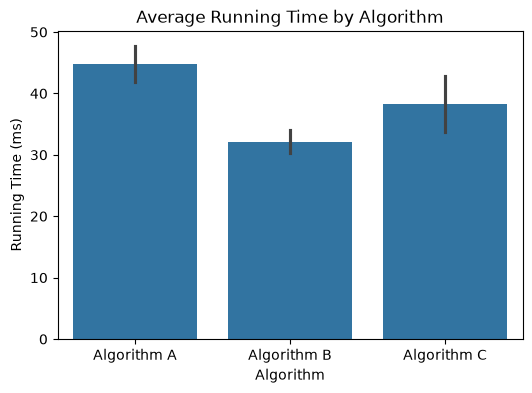

Summary Statistics:
            Runtime_ms      
                  mean   std
Algorithm                   
Algorithm A      44.78  2.99
Algorithm B      32.14  1.84
Algorithm C      38.22  4.57


In [4]:
# Run this cell to view the data
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(data=ex1_data, x='Algorithm', y='Runtime_ms', errorbar='sd', ax=ax)
plt.title("Average Running Time by Algorithm")
plt.ylabel("Running Time (ms)")
plt.show()

print("Summary Statistics:")
print(ex1_stats)

**the summary displays the fact that algorithm A takes the longest to process the data in a repeated study when compared to algorithm B, C.algorithm B takes the least amount of time making it the most time efficent algorithm compared to the other two.**

 we can support these ideas through them mean and standard deviation. while algorithm A has a mean of 44 and std of 2.99, while algorithm B has a mean of 32 and a std of 1.84.

### Exercise II: Network Latency vs. Payload Size

In this exercise, we examine the relationship between network payload size and network latency. The payload is the data being sent in a packet, and latency is how long it takes that data to travel across the network. We collect data on packet size (in MB) and the corresponding latency (in ms) for a set of network transmissions.

Run the cell below to view a scatter plot showing the relationship between payload size and network latency, along with the correlation coefficient ($r$). In the empty Markdown cell, write a summary that accurately describes this plot.

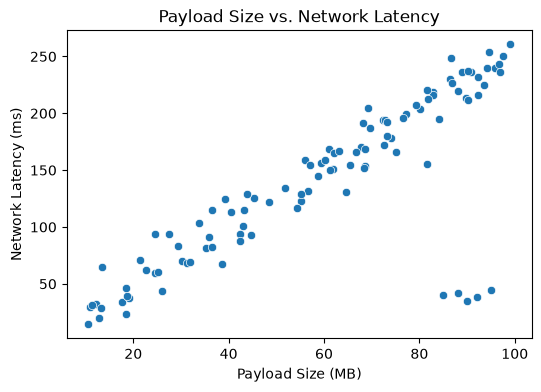

Correlation (r): 0.81


In [5]:
# Run this cell to view the data
fig, ax = plt.subplots(figsize=(6, 4))
sns.scatterplot(data=ex2_data, x='Payload_MB', y='Latency_ms', ax=ax)
plt.title("Payload Size vs. Network Latency")
plt.xlabel("Payload Size (MB)")
plt.ylabel("Network Latency (ms)")
plt.show()

print(f"Correlation (r): {ex2_corr}")

**The summary of this graph is that it has a positive correlation in between the Payload Size and the Network Latency.If the Payload size increases the Network Latency time gradually increases as well.**

 However, there are some outliers that does not fall within the general correlation, sometimes it may have a low network latency time. While the graph has a correlation of 0.81, which is a positive correlation, but the outliers manipulates the correlation, and because of that, we can't make a strong concluation that the correlation is positive. 

### Exercise III: Choosing a Visualization

Below is a written summary from a recent quarterly report. You have been provided with the raw data in the DataFrame `ex3_data`. Write Python code using Seaborn to generate a visualization that perfectly supports this narrative. Ensure your axes are labeled appropriately.

**Report Summary**: 
> "System telemetry reveals a steady, linear upward trend in daily active users over the first three quarters of the year, peaking at the end of Q3. However, this was followed by a sharp and immediate decline throughout Q4."

In [ ]:
ex3_data.head()

,Date,Active_Users
0,2026-01-31,1000
1,2026-02-28,1150
2,2026-03-31,1300
3,2026-04-30,1420
4,2026-05-31,1580


<Axes: xlabel='Date'>

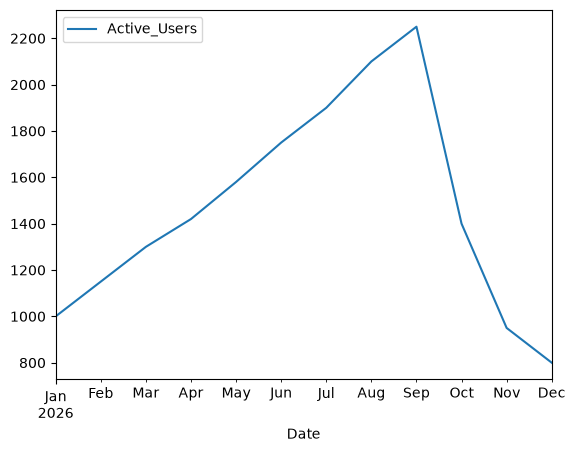

In [14]:
ex3_data.plot.line(x='Date', y='Active_Users')


### Exercise IV: 

Below is a finding from an A/B test evaluating two different server configurations. You have the raw data in `ex4_data`. You must decide which type of Seaborn plot best illustrates this specific claim and write the code to generate it.

**Test Findings**: 
> "While Configuration X delivers a higher median throughput with highly consistent performance, Configuration Y exhibits significantly higher variance. Notably, Configuration Y contains several extreme high-performing outliers, despite its lower overall median."

In [42]:
ex4_data.tail()

,Configuration,Throughput
195,Config Y,52.341415
196,Config Y,54.469491
197,Config Y,74.577019
198,Config Y,77.116670
199,Config Y,63.148200


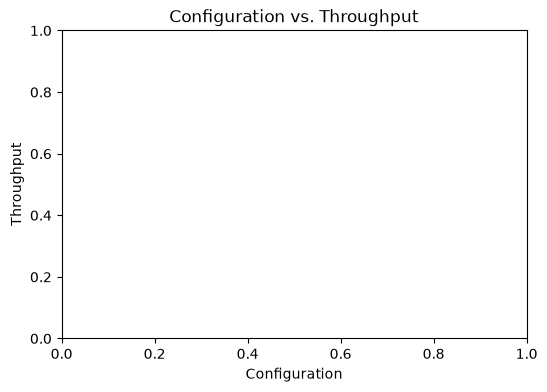

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(6, 4))
plt.title("Configuration vs. Throughput")
plt.xlabel("Configuration")
plt.ylabel("Throughput")
sns.boxplot(data=ex4_data, x='Configuration', y='Throughput', ax=ax)
plt.show()